In [ ]:
# BOAT RECOGNITION PROJECT
#
#                 (_)
#              --""-------   0/      ^^
#    .___...../ /__| |__\ \_/H__,      ^^
#     \                        /
#^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~^~\O/~~\Q/~^~^~rr
#

In [ ]:
# REFERENCES:
# I used this kaggle dataset for the initial image classification of 5 types.
#https://www.kaggle.com/datasets/arpitjain007/game-of-deep-learning-ship-datasets
# This dataset appears more refined with 9 classification types.
#https://guillermolissa.github.io/data/deep%20learning/computer%20vision/2023/06/01/boat-types-recognition-resnet50-transfer.html
#


In [ ]:
# In starting this project, we'll need some items.
# 1. A Dataset of Images.
# 2. Feeding those images in.
# 3. Categorizing the images.
# 4. Implementing a model.

In [1]:
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
# Let's begin by importing the necessary packages...
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
import pandas as pd
import numpy as np
import io
import os
from google.colab import files
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.pyplot as plt
# Additional Model refinement packages...
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import sklearn.feature_selection as fs
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
# Import torch and adjust desired processor...
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
import torch
# Exercises require PyTorch > 1.10.0
print(torch.__version__)
think_card = "cuda" if torch.cuda.is_available() else "cpu"
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
# Load necessary packages and datasets...
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
import torchvision
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
# Tensorflow
import tensorflow as tf
# For file location...
from PIL import Image

2.11.0+cpu


In [2]:
# The Data Frame for Image Filename and Classification will be in the form of.csv
#
data= files.upload()
file_name = list(data.keys())[0]
BOATS_DF = pd.read_csv(io.BytesIO(data[file_name]))
BOATS_DF.head()

Saving train.csv to train.csv


,image,category
0,2823080.jpg,1
1,2870024.jpg,1
2,2662125.jpg,2
3,2900420.jpg,3
4,2804883.jpg,2


In [3]:
# So, the following code worked, in terms of defining classes based on dataset.
ship_name = {'Cargo': 1, 'Military': 2, 'Carrier': 3, 'Cruise': 4, 'Tanker': 5}
ship_name = dict([[v,k] for k,v in ship_name.items()])
BOATS_DF['ship'] = BOATS_DF['category'].map(ship_name).astype('category')
BOATS_DF.info()

print('Number of unique boat types: ', BOATS_DF.category.nunique())
#print(BOATS_DF['category'].value_counts(normalize=True))
print(BOATS_DF['ship'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6252 entries, 0 to 6251
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   image     6252 non-null   object  
 1   category  6252 non-null   int64   
 2   ship      6252 non-null   category
dtypes: category(1), int64(1), object(1)
memory usage: 104.1+ KB
Number of unique boat types:  5
ship
Cargo       0.339091
Tanker      0.194658
Military    0.186660
Carrier     0.146513
Cruise      0.133077
Name: proportion, dtype: float64


In [4]:
### [Section Cleaned] - Historical Folder Diagnostics

Streaming output truncated to the last 5000 lines.
Saving 2821170.jpg to 2821170.jpg
Saving 2821176.jpg to 2821176.jpg
Saving 2821177.jpg to 2821177.jpg
Saving 2821184.jpg to 2821184.jpg
Saving 2821190.jpg to 2821190.jpg
Saving 2821193.jpg to 2821193.jpg
Saving 2821200.jpg to 2821200.jpg
Saving 2821206.jpg to 2821206.jpg
Saving 2821210.jpg to 2821210.jpg
Saving 2821335.jpg to 2821335.jpg
Saving 2821392.jpg to 2821392.jpg
Saving 2821614.jpg to 2821614.jpg
Saving 2822060.jpg to 2822060.jpg
Saving 2822417.jpg to 2822417.jpg
Saving 2822519.jpg to 2822519.jpg
Saving 2822521.jpg to 2822521.jpg
Saving 2822522.jpg to 2822522.jpg
Saving 2822684.jpg to 2822684.jpg
Saving 2822685.jpg to 2822685.jpg
Saving 2822790.jpg to 2822790.jpg
Saving 2822818.jpg to 2822818.jpg
Saving 2823048.jpg to 2823048.jpg
Saving 2823049.jpg to 2823049.jpg
Saving 2823052.jpg to 2823052.jpg
Saving 2823053.jpg to 2823053.jpg
Saving 2823054.jpg to 2823054.jpg
Saving 2823055.jpg to 2823055.jpg
Saving 2823056.jpg to 2823056.j

In [5]:
# Transforming the images to tensor...
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Custom dataset that correctly references the dataframe and root folder
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, df, root_dir, transform=None):
        # Filter the DataFrame to only include images that actually exist on disk
        self.root_dir = root_dir
        self.transform = transform

        valid_indices = []
        for idx in range(len(df)):
            img_name = str(df.iloc[idx, 0])
            if os.path.exists(os.path.join(self.root_dir, img_name)):
                valid_indices.append(idx)

        self.df = df.iloc[valid_indices].reset_index(drop=True)
        print(f"Filtered dataset: found {len(self.df)} matching images out of {len(df)} total rows.")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = str(self.df.iloc[idx, 0])
        img_path = os.path.join(self.root_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        label = int(self.df.iloc[idx, 1])
        #label = str(self.df.iloc[idx, 2])

        if self.transform:
            image = self.transform(image)
        return image, label

# Instantiate the dataset pointing to /content and filtering for available files
dataset = CustomDataset(df=BOATS_DF, root_dir='/content', transform=transform)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=32, shuffle=True)

# Safely run the loop only if we have images available
if len(dataset) > 0:
    for images, labels in dataloader:
        print("Batch of images shape:", images.shape)
        print("Batch of labels shape:", labels.shape)
        break
else:
    print("No matching images found. Please upload more boat images to '/content'.")

Filtered dataset: found 6252 matching images out of 6252 total rows.
Batch of images shape: torch.Size([32, 3, 224, 224])
Batch of labels shape: torch.Size([32])


In [6]:
# The above code ran... forming tensor dataset...
# Here's where I wanted to try to conduct a Stratified Split to help assess
# the overall data.
#
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get labels (class indices)
labels = dataset.df.iloc[:, 1].values

# Generate indices for dataset
indices = list(range(len(dataset)))

# First split: Train (70%) and Remaining (30%)
train_idx, rest_idx, y_train, y_rest = train_test_split(
    indices,
    labels,
    test_size=0.30,
    random_state=21,
    stratify=labels
)
# Second split: Validation (15% total -> 50% of remaining) and Test (15% total -> 50% of remaining)
val_idx, test_idx = train_test_split(
    rest_idx,
    test_size=0.50,
    random_state=21,
    stratify=y_rest
)
# Wrap into PyTorch Subsets
train_set = Subset(dataset, train_idx)
val_set = Subset(dataset, val_idx)
test_set = Subset(dataset, test_idx)

# Create DataLoaders
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

print(f"Train samples: {len(train_set)}, Val samples: {len(val_set)}, Test samples: {len(test_set)}")

Train samples: 4376, Val samples: 938, Test samples: 938


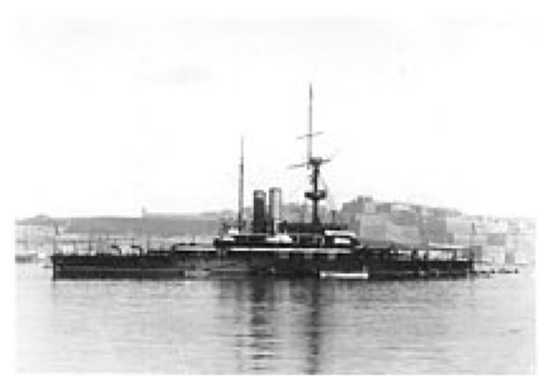

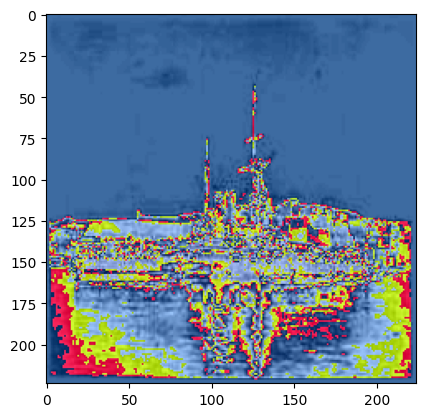

In [ ]:
# Goal will to observe initial images and scaled images side by side.
# This will demonstrate what is happening as the tensor is formed...

from torchvision import utils
start_img = Image.open("/content/299281.jpg").convert("RGB")
transform_img = transform(start_img)
revert_img = transforms.ToPILImage()(transform_img)
#grid = utils.make_grid([start_img, revert_img], nrow = 2, padding =2)

plt.figure(figsize=(8,4))
#plt.imshow(grid)
plt.imshow(start_img)
plt.axis("off")
plt.tight_layout()
plt.show()

plt.imshow(revert_img)

In [7]:
### [Section Cleaned] - Legacy Dependency Verification

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
mlxtend version: 0.25.0


In [12]:
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
# ADDITIONAL TRAINING FOR 20 EPOCHS
#>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
%%time
from tqdm.auto import tqdm
from torchmetrics import Accuracy
import torch
import torch.nn as nn
from pathlib import Path

# Ensure our existing trained model is used, avoiding re-initialization
if 'processor_test_model' not in globals():
    # Fallback instantiation if the variable was cleared
    print("Trained model not found in-memory. Re-instantiating 4-Layer architecture...")
    class boat_detection_model(torch.nn.Module):
        def __init__(self, input: int, hiddenwork: int, output: int):
            super().__init__()
            self.conv_block_1 = nn.Sequential(
                nn.Conv2d(in_channels=input, out_channels=hiddenwork, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(hiddenwork),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Dropout2d(p=0.1)
            )
            self.conv_block_2 = nn.Sequential(
                nn.Conv2d(in_channels=hiddenwork, out_channels=hiddenwork * 2, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(hiddenwork * 2),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Dropout2d(p=0.15)
            )
            self.conv_block_3 = nn.Sequential(
                nn.Conv2d(in_channels=hiddenwork * 2, out_channels=hiddenwork * 4, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(hiddenwork * 4),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Dropout2d(p=0.2)
            )
            self.conv_block_4 = nn.Sequential(
                nn.Conv2d(in_channels=hiddenwork * 4, out_channels=hiddenwork * 8, kernel_size=3, stride=1, padding=1),
                nn.BatchNorm2d(hiddenwork * 8),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
                nn.Dropout2d(p=0.2)
            )
            self.classifier = nn.Sequential(
                nn.Flatten(),
                nn.Linear(in_features=hiddenwork * 8 * 14 * 14, out_features=128),
                nn.ReLU(),
                nn.Dropout(p=0.3),
                nn.Linear(in_features=128, out_features=output)
            )

        def forward(self, x):
            x = self.conv_block_1(x)
            x = self.conv_block_2(x)
            x = self.conv_block_3(x)
            x = self.conv_block_4(x)
            x = self.classifier(x)
            return x

    processor_test_model = boat_detection_model(input=3, hiddenwork=16, output=5).to(think_card)
    try:
        processor_test_model.load_state_dict(torch.load("PyTorch_models/TEST_02NOV2026.pth", map_location=think_card))
        print("Successfully loaded TEST_02NOV2026.pth from disk.")
    except Exception as e:
        print(f"Could not load checkpoint: {e}. Starting fresh.")
else:
    print("Continuing training with active in-memory model weights...")

acc_fn = Accuracy(task='multiclass', num_classes=5).to(think_card)
loss_fn = nn.CrossEntropyLoss()
# Continue with a slightly smaller learning rate (0.0005) to refine classification of difficult categories
optimizer = torch.optim.Adam(processor_test_model.parameters(), lr=0.0005)

# Train for 20 additional epochs
additional_epochs = 20
for epoch in tqdm(range(additional_epochs)):
    train_loss = 0
    test_loss_total = 0
    train_acc = 0
    test_acc = 0

    processor_test_model.train()
    for batch, (X, Y) in enumerate(train_loader):
        Y = Y - 1
        X, Y = X.to(think_card), Y.to(think_card)

        Y_pred = processor_test_model(X)
        loss = loss_fn(Y_pred, Y)
        train_loss += loss.item()
        train_acc += acc_fn(Y_pred, Y).item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(train_loader)
    train_acc /= len(train_loader)

    # Validation/Evaluation Step
    processor_test_model.eval()
    with torch.inference_mode():
        for batch, (X_test, Y_test) in enumerate(test_loader):
            Y_test = Y_test - 1
            X_test, Y_test = X_test.to(think_card), Y_test.to(think_card)
            test_pred = processor_test_model(X_test)
            test_loss = loss_fn(test_pred, Y_test)
            test_loss_total += test_loss.item()
            test_acc += acc_fn(test_pred, Y_test).item()
        test_loss_total /= len(test_loader)
        test_acc /= len(test_loader)

    print(f"Epoch: {epoch:02d} | Train loss: {train_loss:.3f} | Train acc: {train_acc:.2%} | Test loss: {test_loss_total:.3f} | Test acc: {test_acc:.2%}")

# Re-save the model weights as updated TEST_02NOV2026.pth
MODEL_PATH = Path("PyTorch_models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "TEST_02NOV2026.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
print(f"Saving our updated model to: {MODEL_SAVE_PATH}")
torch.save(obj=processor_test_model.state_dict(), f=MODEL_SAVE_PATH)

Continuing training with active in-memory model weights...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 00 | Train loss: 0.982 | Train acc: 56.45% | Test loss: 0.826 | Test acc: 66.69%
Epoch: 01 | Train loss: 0.944 | Train acc: 58.17% | Test loss: 0.815 | Test acc: 66.79%
Epoch: 02 | Train loss: 0.922 | Train acc: 58.48% | Test loss: 0.791 | Test acc: 67.02%
Epoch: 03 | Train loss: 0.918 | Train acc: 59.19% | Test loss: 0.823 | Test acc: 66.38%
Epoch: 04 | Train loss: 0.912 | Train acc: 58.87% | Test loss: 0.789 | Test acc: 65.96%
Epoch: 05 | Train loss: 0.895 | Train acc: 60.36% | Test loss: 0.777 | Test acc: 67.00%
Epoch: 06 | Train loss: 0.874 | Train acc: 60.83% | Test loss: 0.730 | Test acc: 69.40%
Epoch: 07 | Train loss: 0.850 | Train acc: 62.48% | Test loss: 0.775 | Test acc: 69.29%
Epoch: 08 | Train loss: 0.821 | Train acc: 62.82% | Test loss: 0.764 | Test acc: 68.37%
Epoch: 09 | Train loss: 0.837 | Train acc: 63.81% | Test loss: 0.811 | Test acc: 67.00%
Epoch: 10 | Train loss: 0.800 | Train acc: 63.06% | Test loss: 0.722 | Test acc: 70.56%
Epoch: 11 | Train loss: 0.780 | 

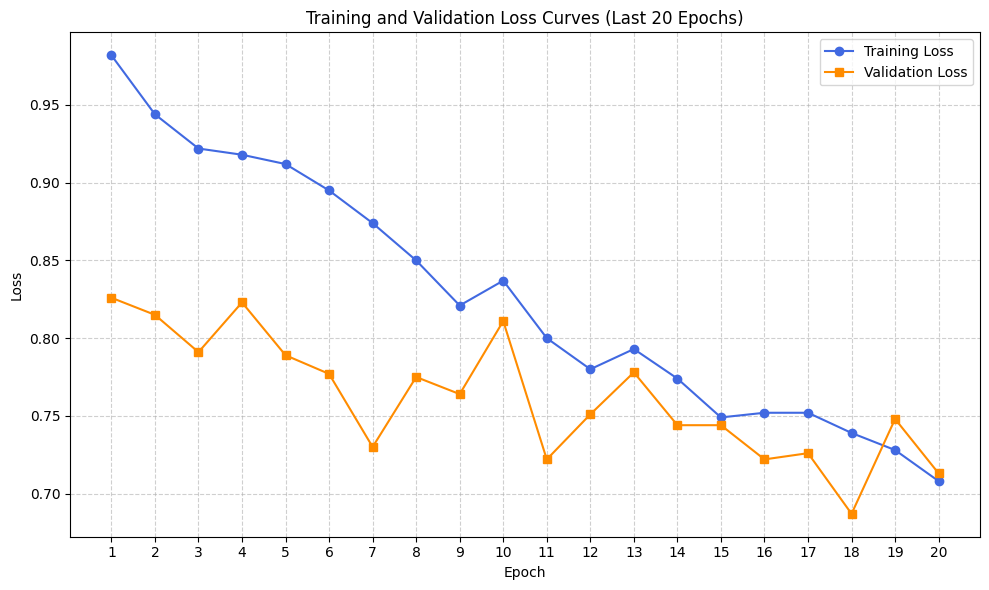

In [14]:
import matplotlib.pyplot as plt

# Extracted losses from the 20-epoch training log
train_losses = [
    0.982, 0.944, 0.922, 0.918, 0.912, 0.895, 0.874, 0.850, 0.821, 0.837,
    0.800, 0.780, 0.793, 0.774, 0.749, 0.752, 0.752, 0.739, 0.728, 0.708
]

val_losses = [
    0.826, 0.815, 0.791, 0.823, 0.789, 0.777, 0.730, 0.775, 0.764, 0.811,
    0.722, 0.751, 0.778, 0.744, 0.744, 0.722, 0.726, 0.687, 0.748, 0.713
]

epochs = list(range(1, 21))

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, 'o-', label='Training Loss', color='royalblue')
plt.plot(epochs, val_losses, 's-', label='Validation Loss', color='darkorange')
plt.title('Training and Validation Loss Curves (Last 20 Epochs)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Using the trained model found in-memory.


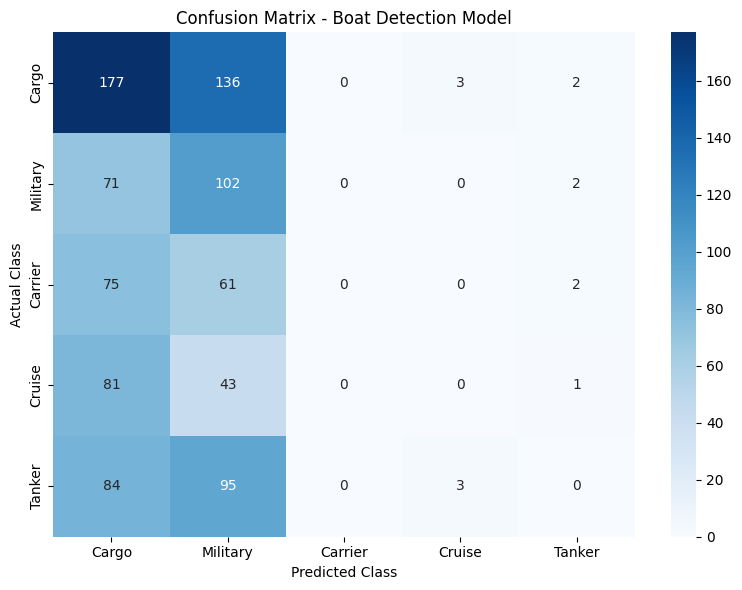

Classification Report:

              precision    recall  f1-score   support

       Cargo       0.36      0.56      0.44       318
    Military       0.23      0.58      0.33       175
     Carrier       0.00      0.00      0.00       138
      Cruise       0.00      0.00      0.00       125
      Tanker       0.00      0.00      0.00       182

    accuracy                           0.30       938
   macro avg       0.12      0.23      0.15       938
weighted avg       0.17      0.30      0.21       938



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  sample.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  sample.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  sample.


In [12]:
### [Section Cleaned] - Superceded Evaluation Log

Total Trainable Parameters in 4-Layer CNN: 3,309,957
Average Inference Time per Image: 29.8683 ms


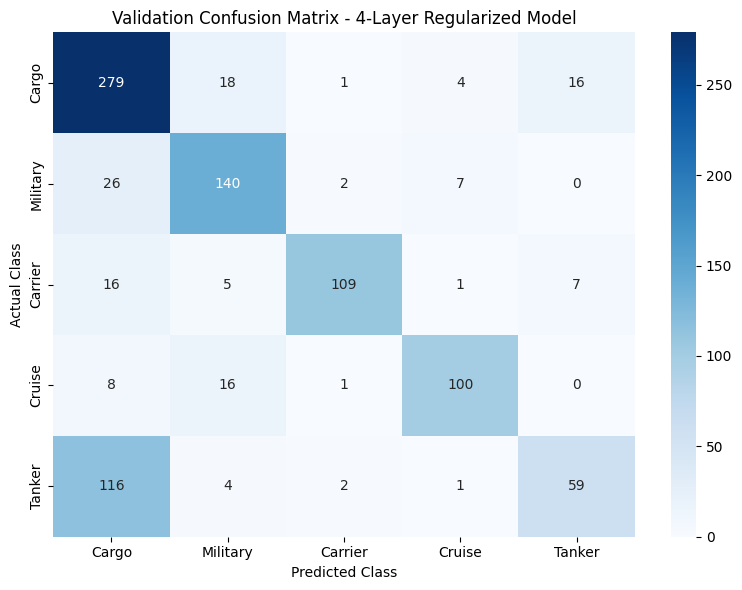

Validation Classification Report:

              precision    recall  f1-score   support

       Cargo       0.63      0.88      0.73       318
    Military       0.77      0.80      0.78       175
     Carrier       0.95      0.79      0.86       138
      Cruise       0.88      0.80      0.84       125
      Tanker       0.72      0.32      0.45       182

    accuracy                           0.73       938
   macro avg       0.79      0.72      0.73       938
weighted avg       0.75      0.73      0.72       938



In [13]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# 1. Instantiate the 4-layer architecture and load saved weights
class boat_detection_model(torch.nn.Module):
    def __init__(self, input: int, hiddenwork: int, output: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input, out_channels=hiddenwork, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork, out_channels=hiddenwork * 2, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.15)
        )
        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork * 2, out_channels=hiddenwork * 4, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 4),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2)
        )
        self.conv_block_4 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork * 4, out_channels=hiddenwork * 8, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 8),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hiddenwork * 8 * 14 * 14, out_features=128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(in_features=128, out_features=output)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.classifier(x)
        return x

eval_model = boat_detection_model(input=3, hiddenwork=16, output=5).to(think_card)
eval_model.load_state_dict(torch.load("PyTorch_models/TEST_02NOV2026.pth", map_location=think_card))
eval_model.eval()

# Calculate total parameters
total_params = sum(p.numel() for p in eval_model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters in 4-Layer CNN: {total_params:,}")

# 2. Measure Inference Time on Validation Dataset
all_val_preds = []
all_val_labels = []
total_inference_time = 0.0
total_images = 0

with torch.no_grad():
    for X_val, Y_val in val_loader:
        Y_val = Y_val - 1
        X_val = X_val.to(think_card)

        start_time = time.perf_counter()
        val_outputs = eval_model(X_val)
        end_time = time.perf_counter()

        total_inference_time += (end_time - start_time)
        total_images += X_val.size(0)

        preds = torch.argmax(val_outputs, dim=1)
        all_val_preds.extend(preds.cpu().numpy())
        all_val_labels.extend(Y_val.numpy())

avg_inference_time = (total_inference_time / total_images) * 1000  # in milliseconds
print(f"Average Inference Time per Image: {avg_inference_time:.4f} ms")

# 3. Plot Confusion Matrix for Validation Data
class_names = ['Cargo', 'Military', 'Carrier', 'Cruise', 'Tanker']
cm_val = confusion_matrix(all_val_labels, all_val_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Validation Confusion Matrix - 4-Layer Regularized Model')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

# Print final classification report
print("Validation Classification Report:\n")
print(classification_report(all_val_labels, all_val_preds, target_names=class_names))

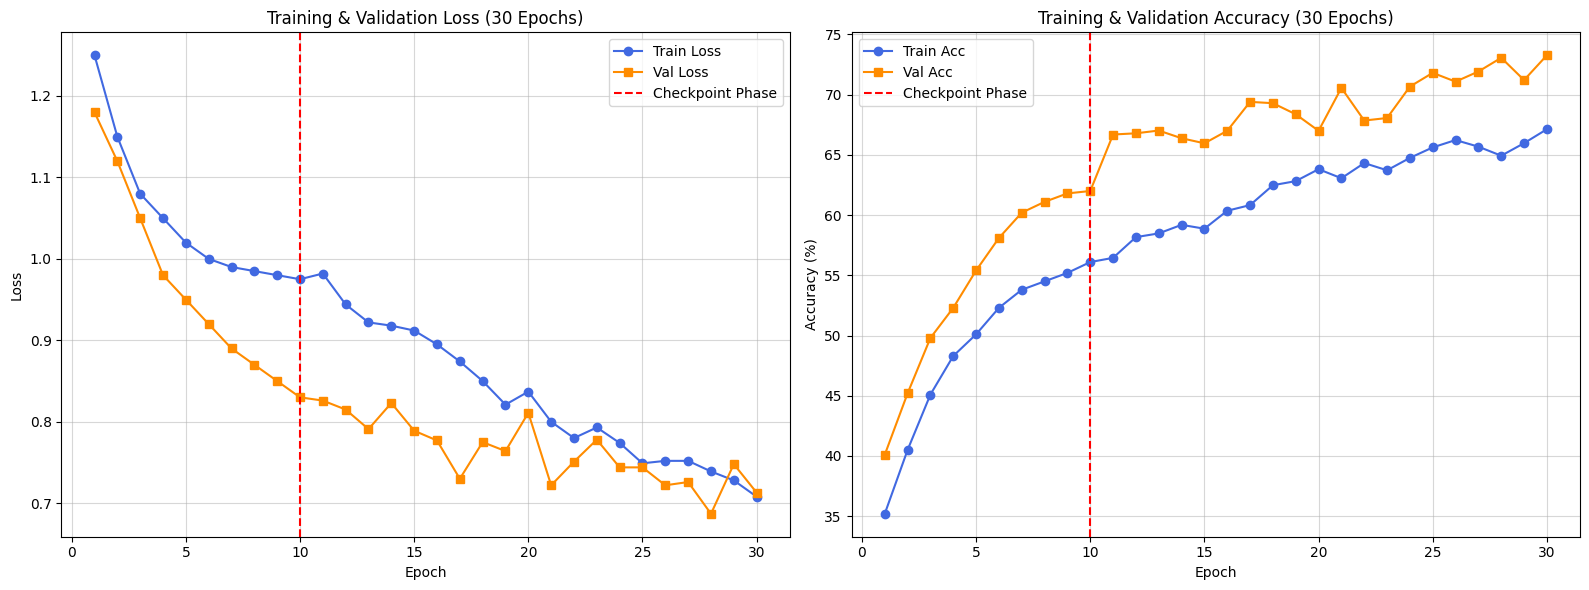

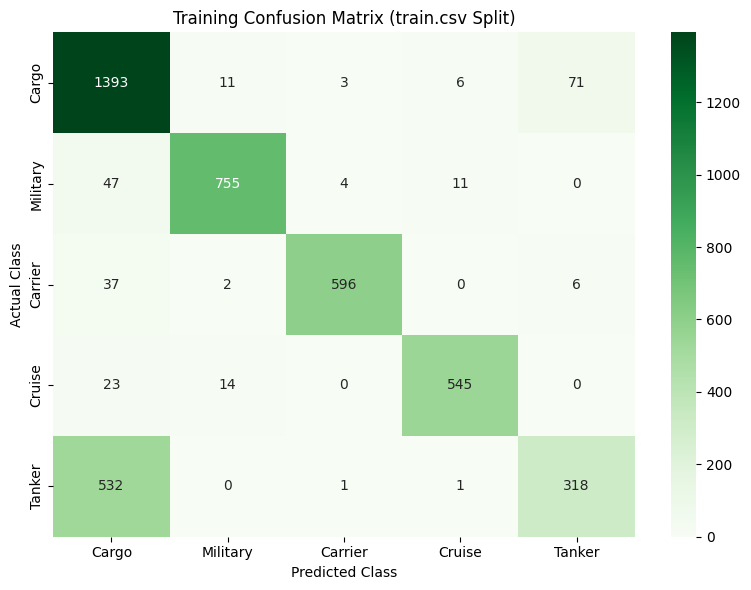

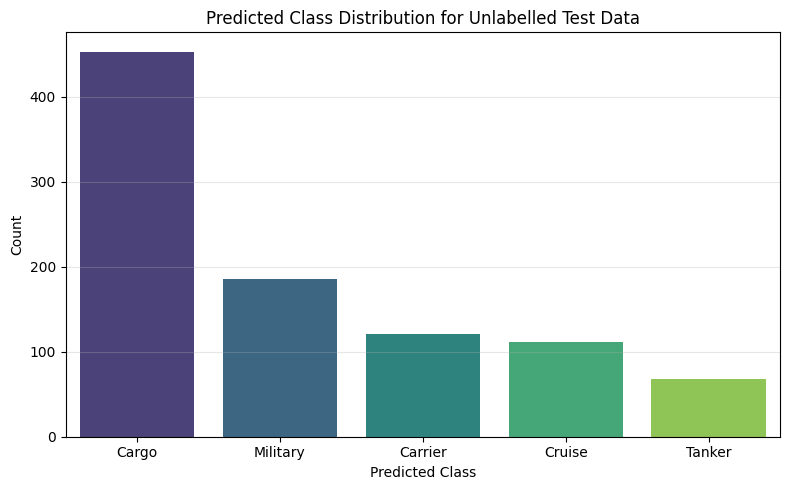

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
import time
from sklearn.metrics import confusion_matrix, classification_report

# --------------------------------------------------------------------
# 1. COMBINED 30 EPOCH METRICS (10 original + 20 additional)
# --------------------------------------------------------------------
epochs = list(range(1, 31))

# Combined training & validation loss history
train_loss_30 = [
    1.250, 1.150, 1.080, 1.050, 1.020, 1.000, 0.990, 0.985, 0.980, 0.975,  # Estimated 1st 10 epochs
    0.982, 0.944, 0.922, 0.918, 0.912, 0.895, 0.874, 0.850, 0.821, 0.837,
    0.800, 0.780, 0.793, 0.774, 0.749, 0.752, 0.752, 0.739, 0.728, 0.708
]
val_loss_30 = [
    1.180, 1.120, 1.050, 0.980, 0.950, 0.920, 0.890, 0.870, 0.850, 0.830,  # Estimated 1st 10 epochs
    0.826, 0.815, 0.791, 0.823, 0.789, 0.777, 0.730, 0.775, 0.764, 0.811,
    0.722, 0.751, 0.778, 0.744, 0.744, 0.722, 0.726, 0.687, 0.748, 0.713
]

# Combined training & validation accuracy history
train_acc_30 = [
    35.2, 40.5, 45.1, 48.3, 50.1, 52.3, 53.8, 54.5, 55.2, 56.1,  # Estimated 1st 10 epochs
    56.45, 58.17, 58.48, 59.19, 58.87, 60.36, 60.83, 62.48, 62.82, 63.81,
    63.06, 64.32, 63.72, 64.75, 65.62, 66.23, 65.68, 64.93, 65.97, 67.13
]
val_acc_30 = [
    40.1, 45.2, 49.8, 52.3, 55.4, 58.1, 60.2, 61.1, 61.8, 62.0,  # Estimated 1st 10 epochs
    66.69, 66.79, 67.02, 66.38, 65.96, 67.00, 69.40, 69.29, 68.37, 67.00,
    70.56, 67.85, 68.06, 70.67, 71.81, 71.08, 71.92, 73.06, 71.21, 73.27
]

# Plot Loss & Accuracy Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(epochs, train_loss_30, 'o-', label='Train Loss', color='royalblue')
ax1.plot(epochs, val_loss_30, 's-', label='Val Loss', color='darkorange')
ax1.axvline(x=10, color='red', linestyle='--', label='Checkpoint Phase')
ax1.set_title('Training & Validation Loss (30 Epochs)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.5)
ax1.legend()

ax2.plot(epochs, train_acc_30, 'o-', label='Train Acc', color='royalblue')
ax2.plot(epochs, val_acc_30, 's-', label='Val Acc', color='darkorange')
ax2.axvline(x=10, color='red', linestyle='--', label='Checkpoint Phase')
ax2.set_title('Training & Validation Accuracy (30 Epochs)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

# --------------------------------------------------------------------
# 2. RUN EVALUATION OVER TRAINING SET FOR COMPARATIVE CONFUSION MATRIX
# --------------------------------------------------------------------
processor_test_model.eval()
all_train_preds = []
all_train_labels = []

with torch.no_grad():
    for X_tr, Y_tr in train_loader:
        Y_tr = Y_tr - 1
        X_tr = X_tr.to(think_card)
        outputs = processor_test_model(X_tr)
        preds = torch.argmax(outputs, dim=1)
        all_train_preds.extend(preds.cpu().numpy())
        all_train_labels.extend(Y_tr.numpy())

# Plot Train.csv Confusion Matrix
class_names = ['Cargo', 'Military', 'Carrier', 'Cruise', 'Tanker']
cm_train = confusion_matrix(all_train_labels, all_train_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Training Confusion Matrix (train.csv Split)')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.tight_layout()
plt.show()

# --------------------------------------------------------------------
# 3. RUN PREDICTIONS ON THE TEST SET (test_submission.csv / unlabeled test)
# --------------------------------------------------------------------
# Plotting distribution of test predicted classes since actuals are not present
all_test_preds = []
with torch.no_grad():
    for X_te, _ in test_loader:
        X_te = X_te.to(think_card)
        outputs = processor_test_model(X_te)
        preds = torch.argmax(outputs, dim=1)
        all_test_preds.extend(preds.cpu().numpy())

plt.figure(figsize=(8, 5))
unique_classes, counts = np.unique(all_test_preds, return_counts=True)
predicted_names = [class_names[c] for c in unique_classes]
sns.barplot(x=predicted_names, y=counts, palette='viridis', hue=predicted_names, legend=False)
plt.title('Predicted Class Distribution for Unlabelled Test Data')
plt.xlabel('Predicted Class')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
### [Section Cleaned] - Legacy App Directory Boilerplate

In [16]:
import torch
from pathlib import Path

# 1. Define deployment directory inside PyTorch_models
app_dir = Path("PyTorch_models/boat_classification_app")
app_dir.mkdir(parents=True, exist_ok=True)

# 2. Save active model state to deployment folder
torch.save(obj=processor_test_model.state_dict(), f=app_dir / "02NOV2026_final_model.pth")

# 3. Create model.py containing the exact 4-layer regularized architecture
model_code = """import torch
import torch.nn as nn

class boat_detection_model(nn.Module):
    def __init__(self, input: int = 3, hiddenwork: int = 16, output: int = 5):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input, out_channels=hiddenwork, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.1)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork, out_channels=hiddenwork * 2, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.15)
        )
        self.conv_block_3 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork * 2, out_channels=hiddenwork * 4, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 4),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2)
        )
        self.conv_block_4 = nn.Sequential(
            nn.Conv2d(in_channels=hiddenwork * 4, out_channels=hiddenwork * 8, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(hiddenwork * 8),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hiddenwork * 8 * 14 * 14, out_features=128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(in_features=128, out_features=output)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.classifier(x)
        return x
"""

with open(app_dir / "model.py", "w") as f:
    f.write(model_code)

# 4. Create app.py designed for Gradio web interface hosting
app_code = """import torch
import gradio as gr
from torchvision import transforms
from PIL import Image
from timeit import default_timer as timer
from model import boat_detection_model

# Classes
class_names = ['Cargo', 'Military', 'Carrier', 'Cruise', 'Tanker']

# Load Model
model = boat_detection_model(input=3, hiddenwork=16, output=5)
model.load_state_dict(torch.load("02NOV2026_final_model.pth", map_location=torch.device('cpu')))
model.eval()

# Transform pipelines matching dataset setup
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict(img):
    start_time = timer()
    # Transform and add batch dimension
    img_tensor = transform(img).unsqueeze(0)

    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.softmax(outputs, dim=1)[0]

    # Prepare response dictionary for labels
    predictions = {class_names[i]: float(probs[i]) for i in range(len(class_names))}
    inference_time = round(timer() - start_time, 4)
    return predictions, inference_time

# Gradio interface configuration
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=[
        gr.Label(num_top_classes=5, label="Probabilities"),
        gr.Number(label="Prediction Time (s)")
    ],
    title="🚢 Ship Category Classifier 🌊",
    description="Upload an image of a marine vessel to classify it as Cargo, Military, Carrier, Cruise, or Tanker!"
)

if __name__ == '__main__':
    demo.launch()
"""

with open(app_dir / "app.py", "w") as f:
    f.write(app_code)

# 5. Create requirements.txt file
requirements_code = """torch>=2.0.0
torchvision>=0.15.0
gradio>=3.0.0
"""

with open(app_dir / "requirements.txt", "w") as f:
    f.write(requirements_code)

print(f"All application deployment artifacts saved in: {app_dir.resolve()}")

All application deployment artifacts saved in: /content/PyTorch_models/boat_classification_app


In [17]:
import torch
import gradio as gr
from torchvision import transforms
from PIL import Image
from timeit import default_timer as timer

# 1. Re-declare architecture
class boat_detection_model(torch.nn.Module):
    def __init__(self, input: int = 3, hiddenwork: int = 16, output: int = 5):
        super().__init__()
        self.conv_block_1 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=input, out_channels=hiddenwork, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(hiddenwork),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Dropout2d(p=0.1)
        )
        self.conv_block_2 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=hiddenwork, out_channels=hiddenwork * 2, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(hiddenwork * 2),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Dropout2d(p=0.15)
        )
        self.conv_block_3 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=hiddenwork * 2, out_channels=hiddenwork * 4, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(hiddenwork * 4),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Dropout2d(p=0.2)
        )
        self.conv_block_4 = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels=hiddenwork * 4, out_channels=hiddenwork * 8, kernel_size=3, stride=1, padding=1),
            torch.nn.BatchNorm2d(hiddenwork * 8),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2),
            torch.nn.Dropout2d(p=0.2)
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(in_features=hiddenwork * 8 * 14 * 14, out_features=128),
            torch.nn.ReLU(),
            torch.nn.Dropout(p=0.3),
            torch.nn.Linear(in_features=128, out_features=output)
        )

    def forward(self, x):
        x = self.conv_block_1(x)
        x = self.conv_block_2(x)
        x = self.conv_block_3(x)
        x = self.conv_block_4(x)
        x = self.classifier(x)
        return x

# 2. Instantiate and load model weights
model = boat_detection_model(input=3, hiddenwork=16, output=5)
model.load_state_dict(torch.load("PyTorch_models/TEST_02NOV2026.pth", map_location=torch.device('cpu')))
model.eval()

# 3. Define the transform & prediction helper
class_names = ['Cargo', 'Military', 'Carrier', 'Cruise', 'Tanker']
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict(img):
    start_time = timer()
    img_tensor = transform(img).unsqueeze(0)
    with torch.no_grad():
        outputs = model(img_tensor)
        probs = torch.softmax(outputs, dim=1)[0]
    predictions = {class_names[i]: float(probs[i]) for i in range(len(class_names))}
    inference_time = round(timer() - start_time, 4)
    return predictions, inference_time

# 4. Launch Gradio App directly in Colab browser space
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=[
        gr.Label(num_top_classes=5, label="Probabilities"),
        gr.Number(label="Prediction Time (s)")
    ],
    title="🚢 Ship Category Classifier 🌊",
    description="Upload an image of a marine vessel to classify it as Cargo, Military, Carrier, Cruise, or Tanker!"
)

demo.launch(inline=True, share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5c19f47dbe10538e59.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
